# 1-01 희석주식수 분석 — 상장주식수 + 전환·행사 가능 물량 + 의무보유

**질문 예시:** "한울앤제주 CB·BW가 다 전환되면 주식수가 얼마나 늘어?", "지금 시장에서 거래될 수 있는 주식은 얼마나 돼?", "보호예수 걸린 물량은?"

종목 하나에 대해 세 가지를 한 표로 모읍니다.

| 항목 | 데이터 출처 |
|---|---|
| 상장주식수·종가 | KRX 정보데이터시스템 전종목 시세 (`krx_data_api.fetch("all_stock_price")`) |
| 발행주식총수(상장 대기분 포함)·고객번호 | SEIBRO Open API `getStkStatInfo` |
| 주식 증감(유상증자·감자·액면분할 등) | SEIBRO Open API `getStkIncdecDetails` |
| 연결된 CB·BW·EB 목록 | SEIBRO Open API `getXrcStkStatInfo` |
| 사채 발행금액·미상환잔액·현재 행사가·BW 납입방법 | SEIBRO 웹 채권 종목상세(`issuInfoViewEL1`, `exerInfoView`, 키 불필요) |
| 누적 전환·행사 실적 | SEIBRO Open API `getXrcStkOptionXrcInfo` |
| 의무보유(보호예수) 예수·반환 | SEIBRO Open API `getSafeDpDutyDepoStatus` |

기본 식은 다음과 같습니다.

- **희석 후 총주식수 = 상장주식수 + 상장 대기 주식 + 전환·행사 가능 주식수(CB·BW)**
- **유통 가능 주식 = 상장주식수 − 의무보유 잔량** (전환 가능 물량은 아직 상장주식이 아니므로 여기서 빼지 않습니다)
- EB는 이미 발행된 주식(주로 자기주식)과 바꾸므로 주식수를 늘리지 않습니다. 따로 보여 줍니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/seibro-api/blob/main/scenarios/combined/01_dilution.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `SEIBRO_API_KEY`, `KRX_ID`, `KRX_PW`를 등록하고 이 노트북의 액세스를 켭니다. SEIBRO Open API 키는 [SEIBRO OpenPlatform](https://seibro.or.kr/OpenPlatform/)에서 신청합니다. 아래 두 셀을 실행해 패키지를 설치하고 실행 환경을 준비하세요.

In [1]:
# Colab에서만: 패키지 설치 (로컬은 이 레포를 pip install -e . 로 설치해 두면 됨)
import sys
if "google.colab" in sys.modules:
    !pip -q install "git+https://github.com/beaten-by-the-market/seibro-api.git" "git+https://github.com/beaten-by-the-market/krx-data-api.git" koreanize-matplotlib

In [2]:
SECRETS = ['SEIBRO_API_KEY', 'KRX_ID', 'KRX_PW']
# ── SEIBRO 공통 셀 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 아래 SECRETS 이름으로 값을 넣고 "노트북 액세스"를 켜세요.
#        SEIBRO_API_KEY = 예탁결제원 SEIBRO Open API 인증키 (https://seibro.or.kr/OpenPlatform)
#        DART_API_KEY = OpenDART 인증키 (DART 데이터를 쓰는 노트북만)
#        KRX_ID / KRX_PW = KRX 정보데이터시스템 계정 (KRX 데이터를 쓰는 노트북만)
# 로컬: 환경변수 또는 작업 폴더(레포 루트)의 .env 를 읽습니다.
# 키·비밀번호 값은 어디에도 출력하지 않습니다. 있는지 여부만 보여 줍니다.
import os, sys, warnings
from datetime import date, datetime, timedelta

import pandas as pd

IN_COLAB = "google.colab" in sys.modules
warnings.filterwarnings("ignore", message="Unverified HTTPS request")

if IN_COLAB and SECRETS:
    from google.colab import userdata
    for _name in SECRETS:  # noqa: F821  (빌더가 이 셀 맨 위에 SECRETS 목록을 넣음)
        if os.environ.get(_name):
            continue
        try:
            _v = userdata.get(_name)
        except Exception:
            _v = None
        if not _v:
            from getpass import getpass
            _v = getpass(f"{_name}: ")
        os.environ[_name] = _v.strip()
elif SECRETS:
    from dotenv import find_dotenv, load_dotenv
    load_dotenv(find_dotenv(usecwd=True))

_missing = [
    n for n in SECRETS  # noqa: F821
    if not os.environ.get(n) and (IN_COLAB or not n.startswith("KRX_"))
]
if _missing:
    raise RuntimeError(f"{_missing} 가 없습니다. Colab Secrets 또는 .env 에 넣어 주세요.")

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def won(v, digits=1):
    """원 → '1.2조' / '5,027억' / '3,400만'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


def shares(v):
    """주식수 → '23,607,980주'."""
    return "-" if v is None or pd.isna(v) else f"{int(v):,}주"


# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

def _status(n):
    if os.environ.get(n):
        return "있음"
    # 로컬에서 krx-data-api를 편집 설치(pip install -e)했다면 그 레포의 .env를 패키지가 직접 읽는다
    return "없음" if IN_COLAB or not n.startswith("KRX_") else "krx-data-api 자체 .env 사용"


credential_status = ", ".join(f"{n}: {_status(n)}" for n in SECRETS)
print("SEIBRO 준비 완료", "(Colab)" if IN_COLAB else "(로컬)",
      "| " + (credential_status or "웹 조회 · 키 필요 없음"))

SEIBRO 준비 완료 (로컬) | SEIBRO_API_KEY: 있음, KRX_ID: krx-data-api 자체 .env 사용, KRX_PW: krx-data-api 자체 .env 사용


In [3]:
STOCK = "276730"     # 한울앤제주: CB 2건·BW 1건, 2026년 감자·액면분할 뒤 의무보유가 다시 등록된 종목
LOOKBACK_YEARS = 5   # 의무보유를 거슬러 조회할 햇수. 이보다 먼저 예수된 물량은 보이지 않습니다
TODAY = date.today()
RESTRUCTURE = ["자본감소", "액면분할", "액면병합", "무상소각"]   # 기존 의무보유 기록을 낡게 만드는 주식수 변경

from krx_data_api import fetch
from seibro_api import (SeibroClient, get_lockup_records, get_stock_issue_details,
                        get_stock_linked_bond_status, lockup_balance)

client = SeibroClient()   # 키는 환경변수 SEIBRO_API_KEY (위 준비 셀)

## 1. 상장주식수와 발행주식총수
KRX 상장주식수는 **시장에서 거래되는 주식**, SEIBRO `TOTAL_STK_CNT`는 **예탁원에 등록된 발행주식 전체**입니다.
유상증자·전환으로 발행됐지만 아직 상장되지 않은 주식이 있으면 SEIBRO 쪽이 더 큽니다.

In [4]:
def krx_snapshot(day):
    """day 또는 그 이전 마지막 거래일의 KRX 전종목 시세(상장주식수 포함). 장중이면 그 시점 값."""
    for i in range(10):
        d = day - timedelta(days=i)
        if d.weekday() >= 5:
            continue
        df = fetch("all_stock_price", trdDd=d.strftime("%Y%m%d"))
        if len(df) and (df["TDD_CLSPRC"].astype(str).str.replace(",", "") != "-").any():
            return d, df
    raise RuntimeError("최근 10일 안에 KRX 시세가 없습니다")


def num(s):
    return pd.to_numeric(pd.Series(s).astype(str).str.replace(",", ""), errors="coerce").iloc[0]


KRX_DAY, snap = krx_snapshot(TODAY)
k = snap[snap["ISU_SRT_CD"] == STOCK].iloc[0]
NAME, MARKET = k["ISU_ABBRV"], k["MKT_NM"]
LISTED, CLOSE = int(num(k["LIST_SHRS"])), num(k["TDD_CLSPRC"])

stk = client.get_stock_info(stock_code=STOCK).iloc[0]
CUSTNO, ISSUED = stk["ISSUCO_CUSTNO"], int(stk["TOTAL_STK_CNT"])
PENDING = max(ISSUED - LISTED, 0)

print(f"{NAME}({STOCK}, {MARKET}) KRX 기준일 {KRX_DAY}  종가 {CLOSE:,.0f}원  액면 {stk['PVAL']}원")
pd.DataFrame({"주식수": [LISTED, ISSUED, ISSUED - LISTED]},
             index=["상장주식수 (KRX)", "발행주식총수 (SEIBRO)", "차이 = 발행됐지만 아직 상장 전"]).style.format("{:,}")

한울앤제주(276730, KOSDAQ) KRX 기준일 2026-11-25  종가 841원  액면 100원


,주식수
상장주식수 (KRX),"23,607,980"
발행주식총수 (SEIBRO),"25,918,180"
차이 = 발행됐지만 아직 상장 전,"2,310,200"


차이가 있으면 상장일이 아직 오지 않은 발행 건을 찾아 봅니다. 주식 증감 내역은 감자·액면분할 같은 이벤트를 찾는 데도 다시 씁니다.

In [5]:
chg = get_stock_issue_details(stock_code=STOCK, client=client, save_csv=False)
chg = chg[chg["종목번호"] == stk["ISIN"]].copy()
chg["발행일자"] = pd.to_datetime(chg["발행일자"], format="%Y%m%d", errors="coerce")
chg["상장일자"] = pd.to_datetime(chg["상장일자"], format="%Y%m%d", errors="coerce")
chg["발행수량"] = pd.to_numeric(chg["발행수량"], errors="coerce")
chg = chg.sort_values("발행일자")
upcoming = chg[chg["상장일자"] > pd.Timestamp(KRX_DAY)]
upcoming[["종목발행사유명", "발행일자", "상장일자", "발행가", "발행수량"]]


[Seibro] 주식수량 변동내역 조회
  단축코드: 276730


  -> 85건 조회 완료


,종목발행사유명,발행일자,상장일자,발행가,발행수량
84,유상증자,2026-11-13,2026-11-27,814,2310200


## 2. 주식관련사채(CB·BW·EB): 아직 주식으로 바뀌지 않은 물량
사채 종류마다 남은 물량을 다르게 셉니다.

| 구분 | 남은 금액 | 이유 |
|---|---|---|
| CB | 미상환잔액 × 행사비율 | 전환하면 사채가 사라지므로 잔액이 곧 미전환분. 조기상환분도 잔액에서 빠져 있음 |
| BW | 발행금액 × 행사비율 − 누적 행사금액 | 신주인수권은 사채와 따로 움직임. 현금 납입이면 행사해도 사채 잔액이 안 줄고, 사채를 조기상환해도 (분리형) 신주인수권은 남음 |
| EB | (참고) 미상환잔액 × 행사비율 | 기존 주식과 교환 → 주식수 불변. 희석에서 제외 |

남은 금액 ÷ **현재 행사가** = 전환·행사 가능 주식수. 행사기간이 이미 끝난 것은 0으로 둡니다.

In [6]:
bonds = get_stock_linked_bond_status(STOCK, client=client)


def remaining(r):
    ratio = (r["행사비율"] if pd.notna(r["행사비율"]) else 100) / 100
    exercised = r["누적행사금액"] if pd.notna(r.get("누적행사금액")) else 0
    if r["구분"] == "BW" and r["행사내역"] in ("있음", "없음"):
        return r["발행금액"] * ratio - exercised, "발행금액−누적행사"
    if r["구분"] == "BW":
        return r["미상환잔액"] * ratio, "미상환잔액(행사내역 조회 실패: 부정확할 수 있음)"
    return r["미상환잔액"] * ratio, "미상환잔액"


bonds[["남은금액", "계산방식"]] = bonds.apply(lambda r: pd.Series(remaining(r)), axis=1)
ended = bonds["행사가능종료일"].notna() & (bonds["행사가능종료일"] < pd.Timestamp(TODAY))
bonds.loc[ended, ["남은금액", "계산방식"]] = [0, "행사기간 종료"]
bonds["전환가능주식수"] = (bonds["남은금액"] // bonds["현재행사가"]).astype("Int64")
bonds["주가/행사가"] = CLOSE / bonds["현재행사가"]

# CB: 발행금액 − 누적 전환금액 − 잔액 = 조기상환·매입소각 등으로 사라진 금액
cb = bonds["구분"] == "CB"
bonds.loc[cb, "상환등추정"] = bonds["발행금액"] - bonds["누적행사금액"].fillna(0) - bonds["미상환잔액"]

# 행사가 점검: 발행(또는 마지막 행사) 뒤에 감자·액면분할·병합이 있었는데 그 뒤 행사 실적이 없으면,
# SEIBRO 행사가가 그 이벤트를 반영했는지 이 데이터만으로는 확인할 수 없습니다.
events = chg[chg["종목발행사유명"].isin(RESTRUCTURE)][["종목발행사유명", "발행일자"]]


def price_check(r):
    seen = [d for d in (r["발행일"], r["최근행사일"]) if pd.notna(d)]
    if not seen:
        return "발행일 모름"
    later = events[events["발행일자"] > max(seen)]
    if later.empty:
        return "-"
    return "확인 필요: " + ", ".join(f"{e}({d:%Y-%m-%d})" for e, d in zip(later["종목발행사유명"], later["발행일자"]))


bonds["행사가점검"] = bonds.apply(price_check, axis=1)

view = bonds[["채권명", "구분", "종류", "발행일", "만기일", "발행금액", "미상환잔액", "누적행사금액",
              "현재행사가", "신주대금납입", "계산방식", "남은금액", "전환가능주식수", "주가/행사가", "행사가점검"]].copy()
for c in ("발행금액", "미상환잔액", "누적행사금액", "남은금액"):
    view[c] = view[c].map(won)
view["주가/행사가"] = view["주가/행사가"].map(lambda v: f"{v:.2f}")
view["현재행사가"] = view["현재행사가"].map(lambda v: f"{v:,.0f}")
view["전환가능주식수"] = view["전환가능주식수"].map(lambda v: "-" if pd.isna(v) else f"{v:,}")
view

[Seibro] 한울앤제주(276730, KR7276730009) 주식관련사채 조회


  -> 3건: CB 2, BW 1


,채권명,구분,종류,발행일,만기일,발행금액,미상환잔액,누적행사금액,현재행사가,신주대금납입,계산방식,남은금액,전환가능주식수,주가/행사가,행사가점검
0,제주맥주 11BW(사모/신/풋),BW,비분리형BW,2025-01-24,2028-01-24,100억,43억,57억,814,대용증권,발행금액−누적행사,43억,"5,288,228",1.03,-
1,한울앤제주12CB(사모/전환),CB,CB,2025-09-30,2028-09-30,34억,34억,0,"18,540",,미상환잔액,34억,"183,387",0.05,"확인 필요: 자본감소(2026-04-14), 액면분할(2026-07-31)"
2,한울앤제주 10CB(사모/전환/풋),CB,CB,2025-05-20,2028-05-20,100억,61억,39억,814,,미상환잔액,61억,"7,495,085",1.03,-


**BW 계산 방식 비교**: 대용납입(사채로 행사대금을 냄)이면 행사할 때 사채도 줄어 두 방식이 거의 같고,
현금납입이면 사채 잔액 기준이 남은 신주인수권을 잘못 셉니다. 원본 스크립트는 모든 사채에 `미상환잔액 // 행사가`를 썼습니다.

In [7]:
bw = bonds[bonds["구분"] == "BW"].copy()
if bw.empty:
    print("BW 없음")
else:
    bw["사채잔액 기준 주식수"] = (bw["미상환잔액"] // bw["현재행사가"]).astype("Int64")
    bw["미행사 신주인수권 기준 주식수"] = bw["전환가능주식수"]
    cols = ["발행금액", "누적행사금액", "미상환잔액", "사채잔액 기준 주식수", "미행사 신주인수권 기준 주식수"]
    display(bw[["채권명", "종류", "신주대금납입"] + cols].style.format({c: "{:,.0f}" for c in cols}))

,채권명,종류,신주대금납입,발행금액,누적행사금액,미상환잔액,사채잔액 기준 주식수,미행사 신주인수권 기준 주식수
0,제주맥주 11BW(사모/신/풋),비분리형BW,대용증권,"10,001,000,000","5,696,381,952","4,304,560,000","5,288,157","5,288,228"


## 3. 의무보유(보호예수) 잔량
`getSafeDpDutyDepoStatus`는 한 번에 1년까지만 조회됩니다. 365일 구간으로 나눠 예수 건과 반환 건을 모두 받고,
예수 건(사유·예수일)마다 반환 수량을 빼서 **남은 수량**을 구합니다.

In [8]:
recs = get_lockup_records(issuco_custno=CUSTNO, years=LOOKBACK_YEARS, client=client)
recs = recs[recs["종목코드"] == STOCK]
recs

[Seibro] 의무보유 예수·반환 조회: 고객번호 30870, 2021-11-27 ~ 2026-11-25 (5개 구간 × 예수/반환)


  -> 예수 7건, 반환 2건


,종목코드,종목명,종목종류,시장,구분,사유코드,사유,예수일,예수주식수,반환일,반환주식수,현재발행주식총수,발행회사고객번호
0,276730,한울앤제주,보통주,코스닥,반환,04,최대주주(코스닥),2021-02-25,0,2023-05-26,12298880,25918180,30870
1,276730,한울앤제주,보통주,코스닥,반환,02,모집(전매제한),2024-12-23,0,2025-12-24,3790751,25918180,30870
2,276730,한울앤제주,보통주,코스닥,예수,02,모집(전매제한),2024-12-23,3790751,NaT,0,25918180,30870
3,276730,한울앤제주,보통주,코스닥,예수,02,모집(전매제한),2025-12-16,6472491,NaT,0,25918180,30870
4,276730,한울앤제주,보통주,코스닥,예수,02,모집(전매제한),2026-04-21,647249,NaT,0,25918180,30870
5,276730,한울앤제주,보통주,코스닥,예수,30,제3자배정유상증자(코스닥),2026-05-27,69725,NaT,0,25918180,30870
6,276730,한울앤제주,보통주,코스닥,예수,02,모집(전매제한),2026-07-31,3236245,NaT,0,25918180,30870
7,276730,한울앤제주,보통주,코스닥,예수,30,제3자배정유상증자(코스닥),2026-07-31,348625,NaT,0,25918180,30870
8,276730,한울앤제주,보통주,코스닥,예수,02,모집(전매제한),2026-08-20,6033235,NaT,0,25918180,30870


**남아 있는 예수 건 점검.** 예탁원은 감자·액면분할·병합이 있으면 기존 기록을 반환 처리하지 않고 바뀐 수량으로 새로 예수합니다.
그래서 이벤트 **이전** 예수 건이 반환 없이 남아 있으면 이후의 새 기록과 같은 주식을 두 번 세는 것일 가능성이 큽니다.

- `재등록의심`: 예수일 뒤에 감자·액면분할·병합·무상소각이 있었던 미반환 건 → 합계에서 뺍니다.
- `1년초과`: 예수 후 1년이 지났는데 미반환인 건. 최대주주·자발적 보호예수처럼 1년을 넘는 게 정상인 사유가 있어 **빼지 않고 표시만** 합니다.
  (원본 스크립트는 "의무보유는 1년을 넘지 않는다"며 380일 초과를 모두 뺐지만, 실제로 최대주주(코스닥) 2년 3개월, 자발적 보호예수 8년 뒤 반환 사례가 있습니다.)

In [9]:
bal = lockup_balance(recs)
held = bal[bal["잔여주식수"] > 0].copy()
LONG_OK = ("최대주주", "자발적", "SPAC", "명목회사", "기타")


def stale_by(dep_date):
    later = events[events["발행일자"] > dep_date]
    return ", ".join(f"{e}({d:%Y-%m-%d})" for e, d in zip(later["종목발행사유명"], later["발행일자"]))


held["경과일"] = (pd.Timestamp(TODAY) - held["예수일"]).dt.days
held["재등록의심"] = held["예수일"].map(stale_by)
held["1년초과"] = [("사유상 가능" if any(x in s for x in LONG_OK) else "확인 필요") if d > 365 else ""
                  for s, d in zip(held["사유"], held["경과일"])]
held["반영"] = held["재등록의심"].eq("")
LOCK_RAW = int(held["잔여주식수"].sum())
LOCK = int(held.loc[held["반영"], "잔여주식수"].sum())
show = held[["사유", "예수일", "예수주식수", "반환주식수", "잔여주식수", "경과일", "재등록의심", "1년초과", "반영"]].copy()
show["예수일"] = show["예수일"].dt.strftime("%Y-%m-%d")
print(f"미반환 잔량 단순 합계 {LOCK_RAW:,}주 → 재등록 의심 제외 {LOCK:,}주 (상장주식수의 {LOCK / LISTED:.1%})")
show.style.format({"예수주식수": "{:,}", "반환주식수": "{:,}", "잔여주식수": "{:,}"})

미반환 잔량 단순 합계 16,807,570주 → 재등록 의심 제외 9,618,105주 (상장주식수의 40.7%)


,사유,예수일,예수주식수,반환주식수,잔여주식수,경과일,재등록의심,1년초과,반영
1,모집(전매제한),2025-12-16,"6,472,491",0,"6,472,491",344,"자본감소(2026-04-14), 액면분할(2026-07-31)",,False
2,모집(전매제한),2026-04-21,"647,249",0,"647,249",218,액면분할(2026-07-31),,False
3,제3자배정유상증자(코스닥),2026-05-27,"69,725",0,"69,725",182,액면분할(2026-07-31),,False
4,모집(전매제한),2026-07-31,"3,236,245",0,"3,236,245",117,,,True
5,제3자배정유상증자(코스닥),2026-07-31,"348,625",0,"348,625",117,,,True
6,모집(전매제한),2026-08-20,"6,033,235",0,"6,033,235",97,,,True


## 4. 종합: 희석 후 주식 구성

In [10]:
CB_SH = int(bonds.loc[bonds["구분"] == "CB", "전환가능주식수"].sum())
BW_SH = int(bonds.loc[bonds["구분"] == "BW", "전환가능주식수"].sum())
EB_SH = int(bonds.loc[bonds["구분"] == "EB", "전환가능주식수"].sum())
FLOAT = LISTED - LOCK
DILUTED = LISTED + PENDING + CB_SH + BW_SH

parts = pd.DataFrame({
    "주식수": [FLOAT, LOCK, PENDING, CB_SH, BW_SH],
}, index=["유통 가능 (상장 − 의무보유)", "의무보유 잔량", "발행 완료·상장 대기", "CB 전환 가능", "BW 행사 가능"])
parts["희석 후 총주식수 대비"] = parts["주식수"] / DILUTED
parts["상장주식수 대비"] = parts["주식수"] / LISTED
summary = pd.DataFrame({"주식수": [LISTED, DILUTED, DILUTED - LISTED, EB_SH]},
                       index=["상장주식수", "희석 후 총주식수", "늘어날 수 있는 주식수", "(참고) EB 교환 대상 — 주식수 불변"])
summary["상장주식수 대비"] = summary["주식수"] / LISTED
display(parts.style.format({"주식수": "{:,}", "희석 후 총주식수 대비": "{:.1%}", "상장주식수 대비": "{:.1%}"}))
summary.style.format({"주식수": "{:,}", "상장주식수 대비": "{:.1%}"})

,주식수,희석 후 총주식수 대비,상장주식수 대비
유통 가능 (상장 − 의무보유),"13,989,875",36.0%,59.3%
의무보유 잔량,"9,618,105",24.7%,40.7%
발행 완료·상장 대기,"2,310,200",5.9%,9.8%
CB 전환 가능,"7,678,472",19.7%,32.5%
BW 행사 가능,"5,288,228",13.6%,22.4%


,주식수,상장주식수 대비
상장주식수,"23,607,980",100.0%
희석 후 총주식수,"38,884,880",164.7%
늘어날 수 있는 주식수,"15,276,900",64.7%
(참고) EB 교환 대상 — 주식수 불변,0,0.0%


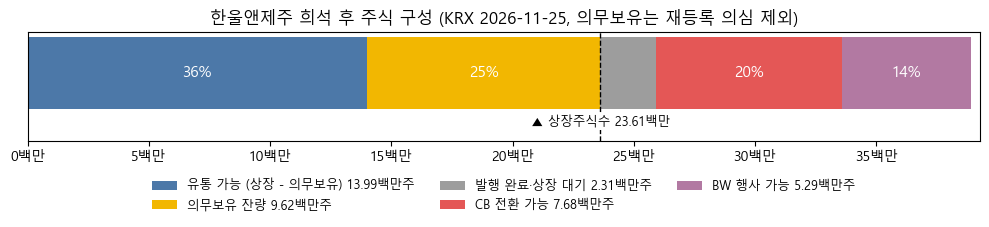

In [11]:
colors = ["#4C78A8", "#F2B701", "#9D9D9D", "#E45756", "#B279A2"]
fig, ax = plt.subplots(figsize=(10, 2.6))
left = 0
for (label, row), c in zip(parts.iterrows(), colors):
    v = row["주식수"]
    if v <= 0:
        continue
    ax.barh(0, v, left=left, color=c, label=f"{label.replace('−', '-')} {v / 1e6:,.2f}백만주")
    if v / DILUTED > 0.06:
        ax.text(left + v / 2, 0, f"{v / DILUTED:.0%}", ha="center", va="center", color="white", fontsize=11)
    left += v
ax.axvline(LISTED, color="black", ls="--", lw=1)
ax.text(LISTED, -0.47, f"▲ 상장주식수 {LISTED / 1e6:,.2f}백만", ha="center", va="top", fontsize=9,
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_yticks([]); ax.set_xlim(0, DILUTED * 1.01); ax.set_ylim(-0.75, 0.45)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1e6:,.0f}백만"))
ax.set_title(f"{NAME} 희석 후 주식 구성 (KRX {KRX_DAY}, 의무보유는 재등록 의심 제외)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False, fontsize=9)
plt.tight_layout()

## 5. 원본 스크립트 방식과 비교
원본 대시보드는 `유통주식 = 상장주식수 − 의무보유(단순 합계) − 전환가능주식수`로 계산하고, 전환 가능 물량을 상장주식 **안의 한 조각**으로 그렸습니다.
아직 발행되지 않은 주식을 상장주식에서 빼면 유통주식이 줄어든 것처럼 보이고, 희석 후 주식수는 오히려 보이지 않습니다.

In [12]:
orig_conv = int((bonds["미상환잔액"] // bonds["현재행사가"]).sum())   # 원본: 모든 사채에 잔액 ÷ 행사가, EB 포함
cmp = pd.DataFrame({
    "원본 방식": [LISTED, LISTED - LOCK_RAW - orig_conv, LISTED],
    "이 노트북": [LISTED, FLOAT, DILUTED],
}, index=["상장주식수", "유통 가능 주식", "희석 후 총주식수"])
cmp.style.format("{:,}")

,원본 방식,이 노트북
상장주식수,"23,607,980","23,607,980"
유통 가능 주식,"-6,166,219","13,989,875"
희석 후 총주식수,"23,607,980","38,884,880"


## 결과 읽는 법과 한계
- **희석률 = 늘어날 수 있는 주식수 ÷ 상장주식수.** 전환 가능 물량은 행사가가 주가보다 낮을수록(`주가/행사가` > 1) 실제로 나올 가능성이 큽니다.
- **행사가는 SEIBRO 기록값**입니다. 리픽싱·감자·액면분할 반영이 늦을 수 있어, 발행(또는 마지막 행사) 뒤 그런 이벤트가 있고 그 뒤 행사가 없으면 `행사가점검`에 표시했습니다.
  행사가가 실제보다 높게 적혀 있으면 전환 가능 주식수는 과소 추정됩니다. 공시(DART 전환가액 조정)로 확인하세요.
- 행사기간 시작 전인 물량도 포함합니다. 행사기간은 행사 실적이 있는 사채만 알 수 있습니다.
- **주식매수선택권(스톡옵션) 미행사분은 포함하지 않았습니다.** SEIBRO에는 미행사 잔량이 없습니다(DART 사업보고서 참고).
- **의무보유는 최근 5년(`LOOKBACK_YEARS`) 예수분만** 봅니다. 그보다 먼저 예수돼 아직 묶인 주식은 빠집니다(과소 추정). 반환 예정일은 API에 없습니다.
- `재등록의심`은 날짜만 보는 규칙입니다. 이벤트 뒤에 같은 수량 비율의 새 예수 기록이 있는지 표에서 직접 확인하세요.
- 상장 대기 주식은 상장 때 의무보유가 새로 걸릴 수 있습니다(아직 기록 없음).